In [2]:
from torchvision import datasets

train_dataset = datasets.MNIST(
    root="../data",
    train=True,
    download=True
)

100.0%
100.0%
100.0%
100.0%


# ML-8: Deep Learning Intro

## Neural Network for MNIST Classification

This project builds and trains a neural network from scratch using PyTorch.

### Objectives
- Load the MNIST dataset
- Prepare train, validation, and test sets
- Build a neural network using PyTorch
- Implement the training loop
- Track training and validation loss
- Compare two neural network architectures
- Evaluate the best model on the test set

In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu
Device: cpu


## 2. Load the MNIST Dataset

MNIST is a handwritten digit classification dataset containing images of digits from 0 to 9.

Each image is grayscale and has a size of 28 × 28 pixels.

We will download the training and test datasets using `torchvision`.

In [3]:
from torchvision import datasets, transforms

# Convert images to PyTorch tensors and normalize pixel values
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Download and load training dataset
train_dataset = datasets.MNIST(
    root="../data",
    train=True,
    download=True,
    transform=transform
)

# Download and load test dataset
test_dataset = datasets.MNIST(
    root="../data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))

Training samples: 60000
Test samples: 10000


## 3. Train-Validation Split

The original MNIST training set contains 60,000 images.

We split it into:
- 90% training data
- 10% validation data

The test set remains completely separate for final evaluation.

In [4]:
from torch.utils.data import random_split

# Set seed for reproducibility
torch.manual_seed(42)

# Split training dataset into train and validation sets
train_size = int(0.9 * len(train_dataset))
val_size = len(train_dataset) - train_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size]
)

print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Test samples:", len(test_dataset))

Training samples: 54000
Validation samples: 6000
Test samples: 10000


## 4. Create DataLoaders

Prepare mini-batches for training, validation, and testing.

In [5]:
from torch.utils.data import DataLoader

batch_size = 64

train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("Batch size:", batch_size)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Batch size: 64
Training batches: 844
Validation batches: 94
Test batches: 157


## 5. Check a Batch

Verify the image and label shapes.

In [6]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels[:10].tolist())

Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
Labels: [5, 1, 4, 5, 1, 1, 3, 5, 5, 8]


## 6. Visualize Sample Images

Display sample MNIST images with their labels.

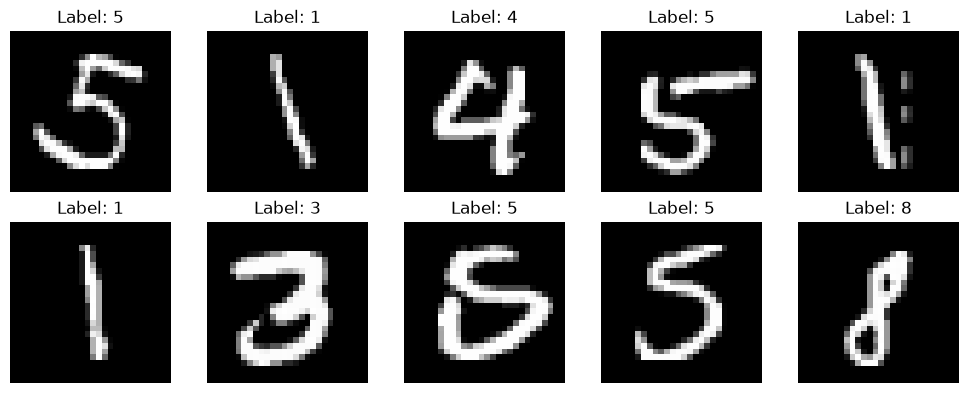

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()


## 7. Define the Neural Network

Build a fully connected neural network with ReLU activation.

In [8]:
import torch.nn as nn

class MNISTNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


model = MNISTNet()

print(model)

MNISTNet(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


## 8. Loss Function and Optimizer

Use Cross-Entropy Loss and the Adam optimizer.

In [9]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", 0.001)

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001


## 9. Training Loop

Train the neural network using forward pass, loss calculation,
backpropagation, and optimizer updates.

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

num_epochs = 5

train_losses = []
val_losses = []

for epoch in range(num_epochs):
    # Training
    model.train()
    running_train_loss = 0.0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()

        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    avg_train_loss = running_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for batch_images, batch_labels in val_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            outputs = model(batch_images)
            loss = criterion(outputs, batch_labels)

            running_val_loss += loss.item()

    avg_val_loss = running_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Validation Loss: {avg_val_loss:.4f}"
    )

Epoch [1/5] Train Loss: 0.2794 | Validation Loss: 0.1627
Epoch [2/5] Train Loss: 0.1191 | Validation Loss: 0.1374
Epoch [3/5] Train Loss: 0.0836 | Validation Loss: 0.1174
Epoch [4/5] Train Loss: 0.0642 | Validation Loss: 0.0978
Epoch [5/5] Train Loss: 0.0507 | Validation Loss: 0.1019


## 10. Training and Validation Loss Curves

Plot the loss curves to monitor learning and overfitting.

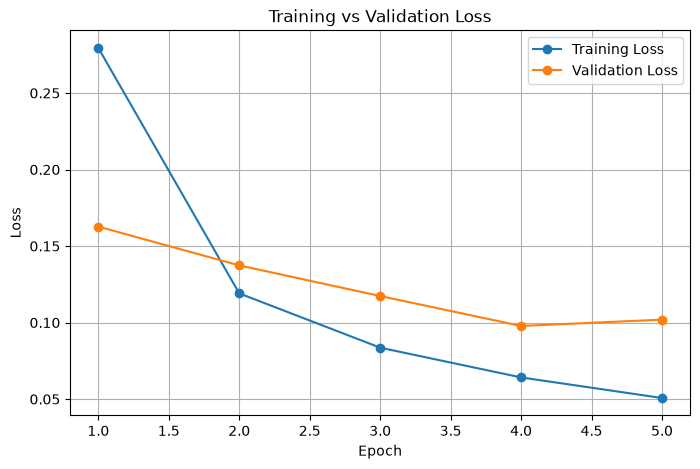

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, num_epochs + 1), train_losses, marker="o", label="Training Loss")
plt.plot(range(1, num_epochs + 1), val_losses, marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## 11. Validation Accuracy

Evaluate the trained model on the validation set.

In [12]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch_images, batch_labels in val_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        outputs = model(batch_images)
        predictions = outputs.argmax(dim=1)

        total += batch_labels.size(0)
        correct += (predictions == batch_labels).sum().item()

val_accuracy = correct / total

print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

Validation Accuracy: 0.9722
Validation Accuracy: 97.22%


## 12. Architecture 2

Train a larger neural network and compare its validation performance with Architecture 1.

In [13]:
class MNISTNetV2(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


model_v2 = MNISTNetV2().to(device)

criterion_v2 = nn.CrossEntropyLoss()
optimizer_v2 = optim.Adam(model_v2.parameters(), lr=0.001)

print(model_v2)

MNISTNetV2(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 13. Train Architecture 2

Train the second architecture using the same training setup.

In [14]:
num_epochs_v2 = 5

train_losses_v2 = []
val_losses_v2 = []

for epoch in range(num_epochs_v2):
    model_v2.train()
    running_train_loss = 0.0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer_v2.zero_grad()

        outputs = model_v2(batch_images)
        loss = criterion_v2(outputs, batch_labels)

        loss.backward()
        optimizer_v2.step()

        running_train_loss += loss.item()

    avg_train_loss = running_train_loss / len(train_loader)
    train_losses_v2.append(avg_train_loss)

    model_v2.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for batch_images, batch_labels in val_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            outputs = model_v2(batch_images)
            loss = criterion_v2(outputs, batch_labels)

            running_val_loss += loss.item()

    avg_val_loss = running_val_loss / len(val_loader)
    val_losses_v2.append(avg_val_loss)

    print(
        f"Epoch [{epoch + 1}/{num_epochs_v2}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Validation Loss: {avg_val_loss:.4f}"
    )

Epoch [1/5] Train Loss: 0.2404 | Validation Loss: 0.1332
Epoch [2/5] Train Loss: 0.0971 | Validation Loss: 0.1067
Epoch [3/5] Train Loss: 0.0694 | Validation Loss: 0.0912
Epoch [4/5] Train Loss: 0.0495 | Validation Loss: 0.0762
Epoch [5/5] Train Loss: 0.0409 | Validation Loss: 0.0984


## 14. Architecture 2 Validation Accuracy

Evaluate the second architecture on the validation set.

In [15]:
model_v2.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch_images, batch_labels in val_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        outputs = model_v2(batch_images)
        predictions = outputs.argmax(dim=1)

        total += batch_labels.size(0)
        correct += (predictions == batch_labels).sum().item()

val_accuracy_v2 = correct / total

print(f"Architecture 2 Validation Accuracy: {val_accuracy_v2:.4f}")
print(f"Architecture 2 Validation Accuracy: {val_accuracy_v2 * 100:.2f}%")

Architecture 2 Validation Accuracy: 0.9712
Architecture 2 Validation Accuracy: 97.12%


## 15. Architecture Comparison

Compare the validation performance of both neural network architectures.

In [16]:
comparison = {
    "Architecture": [
        "784 → 128 → 64 → 10",
        "784 → 256 → 128 → 10"
    ],
    "Validation Accuracy": [
        val_accuracy,
        val_accuracy_v2
    ]
}

for architecture, accuracy in zip(
    comparison["Architecture"],
    comparison["Validation Accuracy"]
):
    print(f"{architecture}: {accuracy * 100:.2f}%")

784 → 128 → 64 → 10: 97.22%
784 → 256 → 128 → 10: 97.12%


## 16. Final Test Evaluation

Evaluate the best-performing architecture on the test set.

In [17]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch_images, batch_labels in test_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        outputs = model(batch_images)
        predictions = outputs.argmax(dim=1)

        total += batch_labels.size(0)
        correct += (predictions == batch_labels).sum().item()

test_accuracy = correct / total

print(f"Final Test Accuracy: {test_accuracy:.4f}")
print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")

Final Test Accuracy: 0.9726
Final Test Accuracy: 97.26%


## 17. Save the Best Model

Save the trained best-performing model for reproducibility.

In [18]:
torch.save(model.state_dict(), "../models/mnist_best_model.pth")

print("Best model saved successfully.")

Best model saved successfully.


## 18. Architecture 2 Loss Curves

Visualize the training and validation loss of the second architecture.

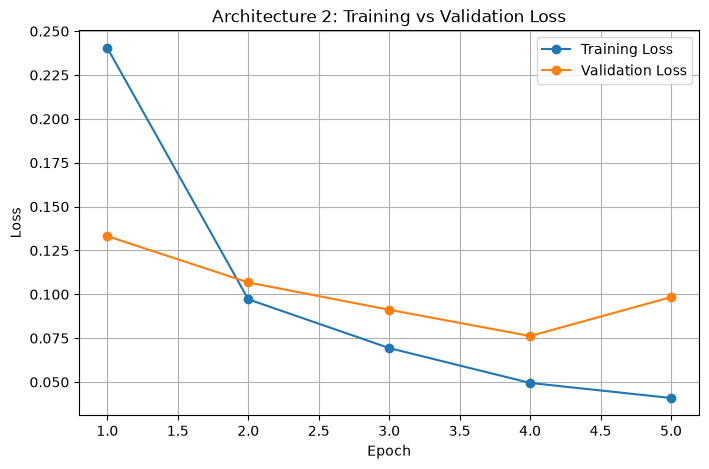

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, num_epochs_v2 + 1),
    train_losses_v2,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, num_epochs_v2 + 1),
    val_losses_v2,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Architecture 2: Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## 19. Final Architecture Comparison

Compare both architectures based on validation and test performance.

In [21]:
results = {
    "Architecture": [
        "784 → 128 → 64 → 10",
        "784 → 256 → 128 → 10"
    ],
    "Validation Accuracy": [
        val_accuracy * 100,
        val_accuracy_v2 * 100
    ],
    "Test Accuracy": [
        test_accuracy * 100,
        None
    ]
}

for i in range(2):
    print(f"Architecture: {results['Architecture'][i]}")
    print(f"Validation Accuracy: {results['Validation Accuracy'][i]:.2f}%")
    
    if results["Test Accuracy"][i] is not None:
        print(f"Test Accuracy: {results['Test Accuracy'][i]:.2f}%")
    else:
        print("Test Accuracy: Not evaluated")
    
    print()

Architecture: 784 → 128 → 64 → 10
Validation Accuracy: 97.22%
Test Accuracy: 97.26%

Architecture: 784 → 256 → 128 → 10
Validation Accuracy: 97.12%
Test Accuracy: Not evaluated



## 20. Conclusion

The neural network successfully classified handwritten MNIST digits using PyTorch.

Two architectures were compared:
- Architecture 1: 784 → 128 → 64 → 10
- Architecture 2: 784 → 256 → 128 → 10

Architecture 1 achieved the best validation accuracy of 97.22% and a final test accuracy of 97.26%.

The loss curves also showed that validation loss generally decreased during training, with slight overfitting in the final epoch.

## 21. Save Training Plots

Save the loss curves for documentation and GitHub presentation.

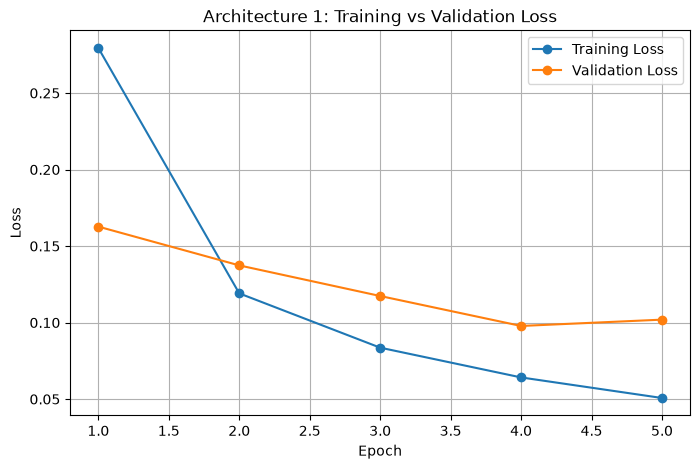

Architecture 1 plot saved.


In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, num_epochs + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, num_epochs + 1),
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Architecture 1: Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.savefig("../plots/architecture1_loss.png", dpi=300, bbox_inches="tight")
plt.show()

print("Architecture 1 plot saved.")

## 22. Save Architecture 2 Plot

Save the training and validation loss curve of the second architecture.

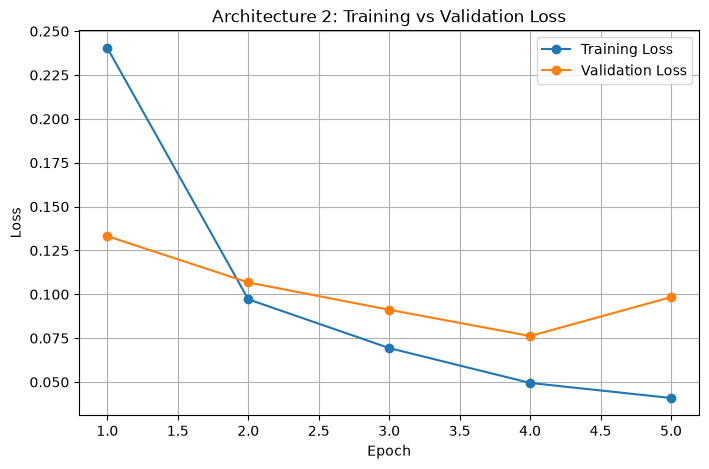

Architecture 2 plot saved.


In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, num_epochs_v2 + 1),
    train_losses_v2,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, num_epochs_v2 + 1),
    val_losses_v2,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Architecture 2: Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.savefig("../plots/architecture2_loss.png", dpi=300, bbox_inches="tight")
plt.show()

print("Architecture 2 plot saved.")

## 23. Final Results Summary

| Model | Validation Accuracy | Test Accuracy |
|---|---:|---:|
| Architecture 1 (784 → 128 → 64 → 10) | 97.22% | **97.26%** |
| Architecture 2 (784 → 256 → 128 → 10) | 97.12% | Not evaluated |

### Best Model
Architecture 1 achieved the best validation performance and was selected for final testing.

**Final Test Accuracy: 97.26%**